In [1]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict
from dotenv import load_dotenv

### Load Env Variables

In [2]:
load_dotenv()

True

### Define LLM

In [5]:
model  = ChatGoogleGenerativeAI(
    model="gemini-3.6-flash"
)

### Define State

In [6]:
class JobState(TypedDict):
    job_title: str
    skills: str
    interview_plan: str

### Creating Nodes
First Node: Creating Skills list

In [ ]:
def identify_skills(state: JobState) -> JobState:

    # Get job title from state
    job_title = state['job_title']

    # Create prompt
    prompt = f"""
    Identify the most important technical and soft skills
    required for the job role: {job_title}

    Give the skills in a clear and organized list.
    """

    # Call LLM
    skills = model.invoke(prompt).content

    # Update state
    state['skills'] = skills

    return state

Second Node: Create interview preperation plan

In [8]:
def create_interview_plan(state: JobState) -> JobState:

    # Get information from state
    job_title = state['job_title']
    skills = state['skills']

    # Create prompt using output of previous node
    prompt = f"""
    Create a detailed interview preparation plan for the
    job role: {job_title}

    The candidate should prepare for the following skills:

    {skills}

    Organize the preparation plan into:
    1. Technical topics
    2. Practical exercises
    3. Common interview questions
    4. Final preparation tips
    """

    # Call LLM
    interview_plan = model.invoke(prompt).content

    # Update state
    state['interview_plan'] = interview_plan

    return state

### Define and Compile Graph

In [9]:
# Define Graph
graph = StateGraph(JobState)

# Add Nodes
graph.add_node('identify_skills', identify_skills)
graph.add_node('create_interview_plan', create_interview_plan)

# Add edges
graph.add_edge(START, 'identify_skills')
graph.add_edge('identify_skills', 'create_interview_plan')
graph.add_edge('create_interview_plan', END)

# compile graph
workflow = graph.compile()

### Execute Graph

In [10]:
initial_state = {
    'job_title': 'Python Developer'
}

final_state = workflow.invoke(initial_state)

print("Required Skills:")
print(final_state['skills'])

print("\nInterview Preparation Plan:")
print(final_state['interview_plan'])

Required Skills:
[{'type': 'text', 'text': 'Here is a clear and organized list of the most important **technical** and **soft skills** required for a **Python Developer** role.\n\n---\n\n### **1. Technical Skills (Hard Skills)**\n\n#### **A. Core Python Proficiency**\n*   **Object-Oriented & Functional Programming:** Deep understanding of OOP concepts (Classes, Inheritance) and functional paradigms (Lambda functions, Generators, Decorators).\n*   **Data Structures & Algorithms:** Expertise in built-in data types (Lists, Dicts, Sets, Tuples) and efficient algorithm design.\n*   **Asynchronous Programming:** Familiarity with `asyncio`, multi-threading, and multi-processing for performance optimization.\n\n#### **B. Frameworks & Libraries**\n*   **Web Frameworks:** Experience with **Django**, **Flask**, or **FastAPI** for building backend web applications and RESTful APIs.\n*   **Data Analysis & Science (if applicable):** Familiarity with **Pandas**, **NumPy**, **SciPy**, **Matplotlib**, 

### Visualize graph

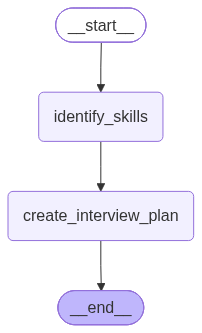

In [11]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())